# Tugas 3 SK5001 Metode Sains Komputasi

Nama: T. M. Aldine Al Kautsar

NIM: 20926005

## Integrasi Monte Carlo

$$\int_0^5 \int_0^5 2x^2 - y^2 dx dy$$

Solusi Analitik: $\frac{625}{3} \approx 208.3$

In [124]:
import numpy as np
from matplotlib import pyplot as plt

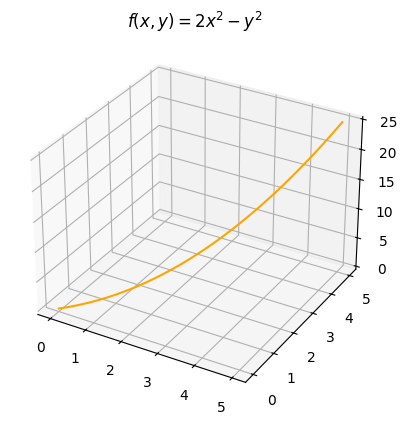

In [125]:
def f(x, y):
    return 2*x**2 - y**2

x = np.arange(0, 5, 0.01)
y = np.arange(0, 5, 0.01)
z = f(x, y)

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.plot(x, y, z, color='orange')
plt.title('$f(x,y) = 2x^2 - y^2$')
plt.show()

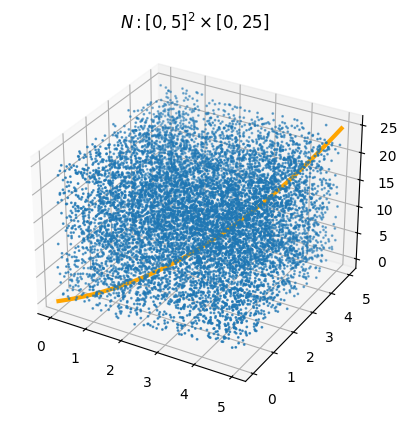

In [126]:
x_points = []
y_points = []
z_points = []

N = 10000

for i in range(N):
    x_points.append(np.random.uniform(0,5))
    y_points.append(np.random.uniform(0,5))
    z_points.append(np.random.uniform(0,max(z)))

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(x_points, y_points, z_points, s=1)
ax.plot(x, y, z, color='orange', linewidth=3)
plt.title('$N: [0, 5]^2 \\times [0,25]$')
plt.show()

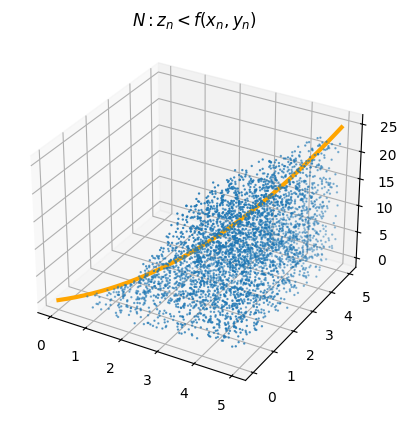

In [127]:
x_in = []
y_in = []
z_in = []

for i in range(N):
    if z_points[i] < f(x_points[i], y_points[i]):
        x_in.append(x_points[i])
        y_in.append(y_points[i])
        z_in.append(z_points[i])

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(x_in, y_in, z_in, s=0.5)
ax.plot(x, y, z, color='orange', linewidth=3)
plt.title('$N: z_n < f(x_n, y_n)$')
plt.show()

Metode Rata-Rata:

$$I \approx \frac{(b_x - a_x) (b_y - a_y)}{N} \sum_{i=1}^{N} f(x_i)$$

In [128]:
a = 0
b = 5
N_total = len(z_points)
sum_fx = sum(f(np.array(x_points), np.array(y_points)))
I = (b - a)**2 / N_total * sum_fx
print(f'I approx = {I:.2f}')

I approx = 209.48


Buat sebuah tabel yang membandingkan solusi Monte Carlo dengan $N = 100, 1000, 10000$, dan solusi analitik. Bandingkan pula galatnya dengan hasil solusi analitik.

In [129]:
def montecarlo(N):
    x_points = []
    y_points = []
    z_points = []
    for i in range(N):
        x_points.append(np.random.uniform(0,5))
        y_points.append(np.random.uniform(0,5))
        z_points.append(np.random.uniform(0,max(z)))
    
    x_in = []
    y_in = []
    z_in = []
    for i in range(N):
        if z_points[i] < f(x_points[i], y_points[i]):
            x_in.append(x_points[i])
            y_in.append(y_points[i])
            z_in.append(z_points[i])

    a = 0
    b = 5
    N_total = len(z_points)
    sum_fx = sum(f(np.array(x_points), np.array(y_points)))
    I = (b - a)**2 / N_total * sum_fx
    return I

N = [100, 1000, 10000]

print('Solusi Analitik = 208.3\n')
print('    N      Solusi Monte Carlo      Error')
print('---------------------------------------------')
for n in N:
    sol = montecarlo(n)
    print(f'{n:^10} |    {sol:.2f}     |     {np.abs(sol - 208.3):.6f}')

Solusi Analitik = 208.3

    N      Solusi Monte Carlo      Error
---------------------------------------------
   100     |    212.24     |     3.944084
   1000    |    204.83     |     3.472401
  10000    |    207.27     |     1.030436


## Accept/Reject Sampling

$$p(x) = \omega N (\mu_1, \sigma_1) + (1 - \omega) N(\mu_2, \sigma_2)$$

Dengan $N(\mu, \sigma)$ fungsi Normal

$$N(\mu, \sigma) = \frac{1}{\sigma \sqrt{2 \pi}} e^{-\frac{1}{2}(\frac{x-\mu}{\sigma})^2}$$

Dengan $\omega = 0.2$, $\mu_1 = -2$, $\sigma_1 = 2$, $\mu_2 = 7$, $\sigma_2 = 1$, ambilah $1000$ sampel dari $p(x)$ dengan menggunakan metode *accept/reject* pada rentang $[-15, 15]$

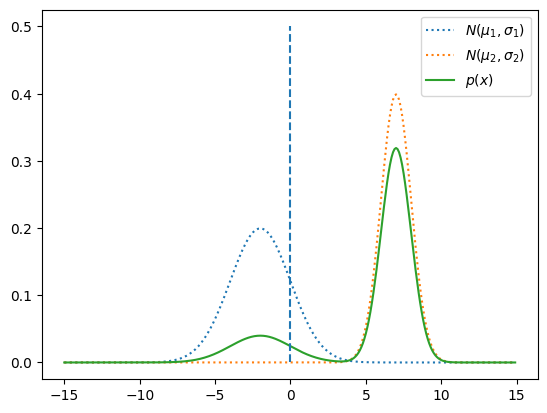

In [130]:
w = 0.2
u1 = -2
s1 = 2
u2 = 7
s2 = 1

x = np.arange(-15, 15, 0.1)

def normal(x, u, sigma):
    return np.exp(-0.5 * ((x - u) / sigma)**2) / (sigma * np.sqrt(2*np.pi)) 

def p(x):
    return w * normal(x, u1, s1) + (1 - w) * normal(x, u2, s2)

plt.plot(x, normal(x, u1, s1), linestyle=':', label='$N(\\mu_1, \\sigma_1)$')
plt.plot(x, normal(x, u2, s2), linestyle=':', label='$N(\\mu_2, \\sigma_2)$')
plt.plot(x, p(x), label='$p(x)$')
plt.vlines(0, 0, 0.5 , linestyles='--')
plt.legend()
plt.show()

Encapsulasi $p(x)$ menggunakan distribusi normal $g(x) = N(\mu, \sigma)$ 

dengan:
$\mu = 7.5$, $\sigma = 9$

dan *scaling constant* $C = 8$

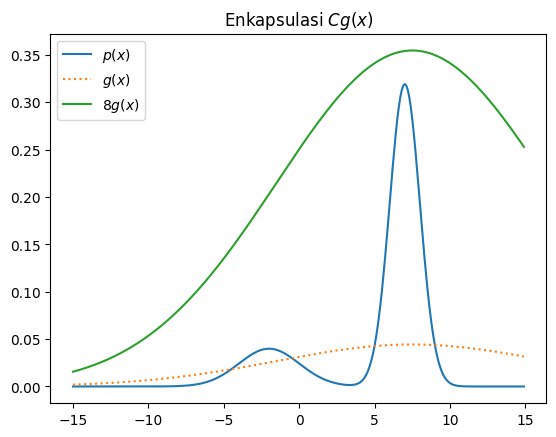

In [139]:
C = 8
u3 = 7.5
s3 = 9

plt.plot(x, p(x), label='$p(x)$')
plt.plot(x, normal(x, u3, s3), linestyle=':', label='$g(x)$')
plt.plot(x, C*normal(x, u3, s3), label='$8g(x)$')
plt.legend()
plt.title('Enkapsulasi $Cg(x)$')
plt.show()

$1000$ sampel yang mengikuti distribusi $ N(7.5, 9)$

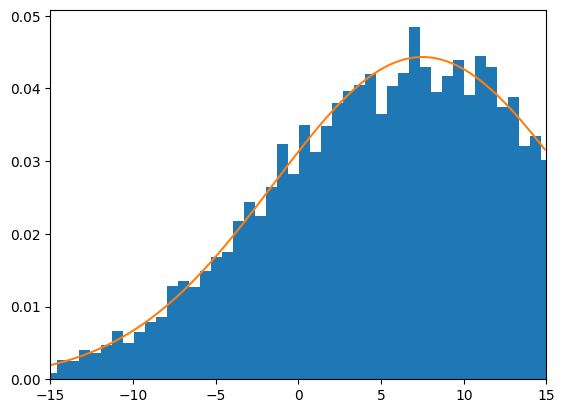

In [132]:
x_sample = []
r_sample = []

accept = []

N = 10000

for i in range(N):
    X = (np.random.normal(u3, s3))
    Y = (np.random.uniform(0,1))
    x_sample.append(X)
    r_sample.append(Y)

plt.hist(x_sample, bins=100, density=True)
plt.plot(x, normal(x, u3, s3))
plt.xlim(-15, 15)
plt.show()

Buatlah plot yang menunjukkan histogram sampel-sampel yang diambil dan bandingkan dengan plot persamaan $p(x)$.

*Accept* jika:

$$r_n < \frac{p(x_n)}{C \times g(x_n)}$$

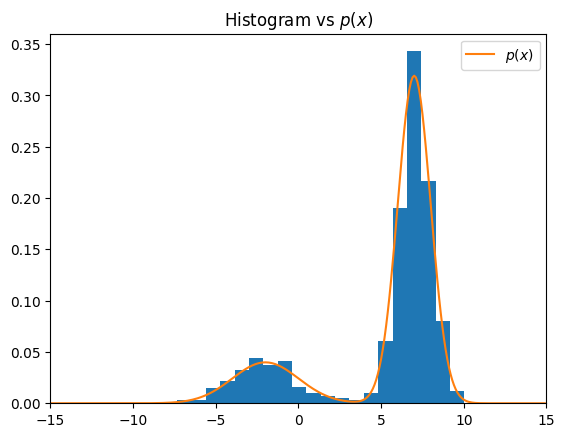

In [137]:
accept = []

for i in range(N):
    if r_sample[i] < p(x_sample[i]) / (C * normal(x_sample[i], u3, s3)):
        accept.append(x_sample[i])

plt.hist(accept, bins=20, density=True)
plt.plot(x, p(x), label='$p(x)$')
plt.xlim(-15, 15)
plt.legend()
plt.title('Histogram vs $p(x)$')
plt.show()